# 实验六 A · 六色版画风格迁移
用条件 GAN 将自然照片变成固定调色板的版画。比较对抗损失与重构损失的权重，结合测试图与训练演化观察结构和风格。

In [1]:
from pathlib import Path
import sys, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision.transforms.functional import to_tensor
from torch.utils.data import TensorDataset, DataLoader
from skimage.metrics import structural_similarity
root = Path('exp6' if Path('exp6/data_index.csv').exists() else '.').resolve()
sys.path.insert(0, str(root))
from style_data import photo, poster, PALETTE
out = root/'results'/'exp6A'; out.mkdir(parents=True, exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(4)
seed = 6026
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('设备', device)
import torch.nn.functional as F
colors = torch.tensor(PALETTE.copy(), dtype=torch.float32, device=device)/127.5-1

设备 cuda


## 数据与监督目标
按原清单读取 256 张训练图与 40 张独立测试图，中心裁剪为 192×192。用中值滤波和亮度分段制作六色目标，将其编码为 0 至 5 的色号。训练时从每张配对图随机取相同位置的 96×96 区域，测试时输入整张照片。另外在原版 96×96 测试条件下复评，便于直接对照。

In [2]:
index = pd.read_csv(root/'data_index.csv')
def load_pairs(split, size):
    photos, labels = [], []
    for row in index[index.split == split].itertuples():
        image = photo(row, root, size)
        target = np.asarray(poster(image))
        # 六色的红通道各不相同，可无损还原其调色板索引。
        label = np.searchsorted(PALETTE[:,0], target[:,:,0])
        photos.append(to_tensor(image)*2-1)
        labels.append(torch.from_numpy(label).long())
    return torch.stack(photos), torch.stack(labels)
train_x, train_labels = load_pairs('train',192)
test_sets = {size:load_pairs('test',size) for size in (96,192)}
print(len(train_x), '张训练图，',len(test_sets[192][0]),'张测试图')

256 张训练图， 40 张测试图


## 生成器与条件判别器
生成器用保持分辨率的卷积学习局部结构，为每个位置预测六个色号的分数。训练时用概率加权的 RGB 图计算对抗与重构损失，另用交叉熵监督色号。展示和测试时统一取最高分色号。条件判别器接收照片及对应的候选版画。

In [3]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3,24,3,padding=1,padding_mode='replicate'), nn.LeakyReLU(0.2),
                                      nn.Conv2d(24,24,3,padding=1,padding_mode='replicate'), nn.LeakyReLU(0.2),
                                      nn.Conv2d(24,24,3,padding=1,padding_mode='replicate'), nn.LeakyReLU(0.2))
        self.head = nn.Conv2d(27,6,1)
    def forward(self, x):
        return self.head(torch.cat([x,self.features(x)],dim=1))

def discriminator():
    layers=[]
    for a,b in [(6,24),(24,48),(48,96)]:
        layers.extend([nn.Conv2d(a,b,4,2,1),nn.GroupNorm(4,b),nn.LeakyReLU(0.2)])
    return nn.Sequential(*layers,nn.Conv2d(96,1,3,padding=1))

def color_image(labels):
    return colors[labels].permute(0,3,1,2).contiguous()

def rgb(t):
    return ((t.detach().cpu().permute(1,2,0).numpy()+1)/2).clip(0,1)

## 对照训练
每组训练 40 轮，保持初值、训练顺序、裁剪随机种子、交叉熵权重和优化器一致。生成器损失为 BCE + λ × L1 + 色号交叉熵，分别取 λ=1 和 50。记录第 1、10、40 轮同一测试图。

In [4]:
weights = [1,50]; epochs = 40
history, evolution, predictions = [], {}, {}
bce = nn.BCEWithLogitsLoss()
for weight in weights:
    torch.manual_seed(seed)
    crops = random.Random(seed)
    loader = DataLoader(TensorDataset(train_x,train_labels),batch_size=16,shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    g,d = Generator().to(device),discriminator().to(device)
    opt_g,opt_d = [torch.optim.Adam(m.parameters(),lr=0.0005,betas=(0.5,0.999)) for m in (g,d)]
    for epoch in range(1,epochs+1):
        sums = np.zeros(4)
        for photos,labels in loader:
            top,left = crops.randrange(97),crops.randrange(97)
            x = photos[:,:,top:top+96,left:left+96].to(device)
            labels = labels[:,top:top+96,left:left+96].to(device)
            y = color_image(labels)
            logits = g(x)
            fake = F.conv2d(logits.softmax(1),colors.T.contiguous()[:,:,None,None])
            real_scores = d(torch.cat([x,y],1)); fake_scores = d(torch.cat([x,fake.detach()],1))
            loss_d = (bce(real_scores,torch.ones_like(real_scores))+bce(fake_scores,torch.zeros_like(fake_scores)))/2
            opt_d.zero_grad(); loss_d.backward(); opt_d.step()
            d.requires_grad_(False)
            scores = d(torch.cat([x,fake],1))
            adv = bce(scores,torch.ones_like(scores)); l1 = F.l1_loss(fake,y); ce = F.cross_entropy(logits,labels)
            opt_g.zero_grad(); (adv+weight*l1+ce).backward(); opt_g.step(); d.requires_grad_(True)
            sums += [adv.item(),l1.item(),loss_d.item(),ce.item()]
        history.append([weight,epoch,*(sums/len(loader))])
        if epoch in [1,10,epochs]:
            with torch.no_grad():
                label = g(test_sets[192][0][:1].to(device)).argmax(1)
                evolution[weight,epoch] = rgb(color_image(label)[0])
    with torch.no_grad():
        for size,(xs,_) in test_sets.items():
            predictions[weight,size] = torch.cat([g(x.to(device)).argmax(1).cpu() for x in xs.split(4)])
hist = pd.DataFrame(history,columns=['lambda_l1','epoch','adversarial','l1','discriminator','color_ce'])
hist.to_csv(out/'loss.csv',index=False)

## 整图评价
在每张测试图上分别计算 MAE、结构相似度 SSIM 和正确色号像素比例。六色输出由模型结构保证，评价重点是每种颜色放置的位置。使用测试清单前四张图展示，按最近邻显示离散色块。

MAE      SSIM  pixel_accuracy
size lambda_l1                                    
96   1          0.021605  0.782519        0.883176
     50         0.020215  0.791934        0.891474
192  1          0.018176  0.808464        0.900458
     50         0.016956  0.817605        0.907412

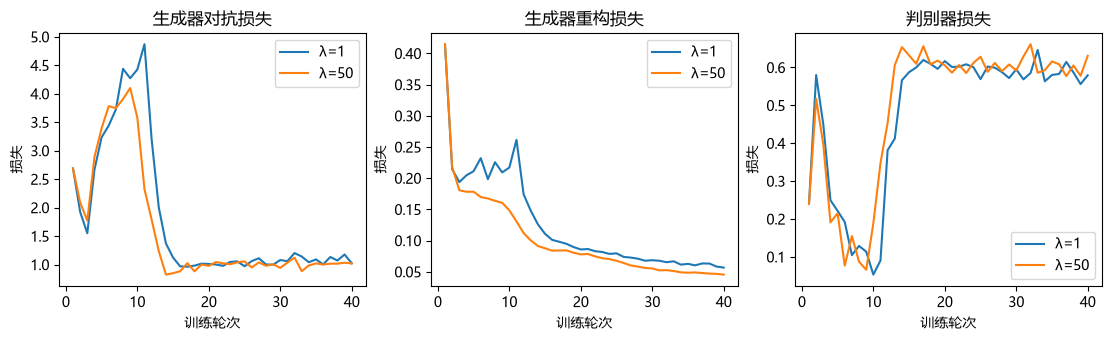

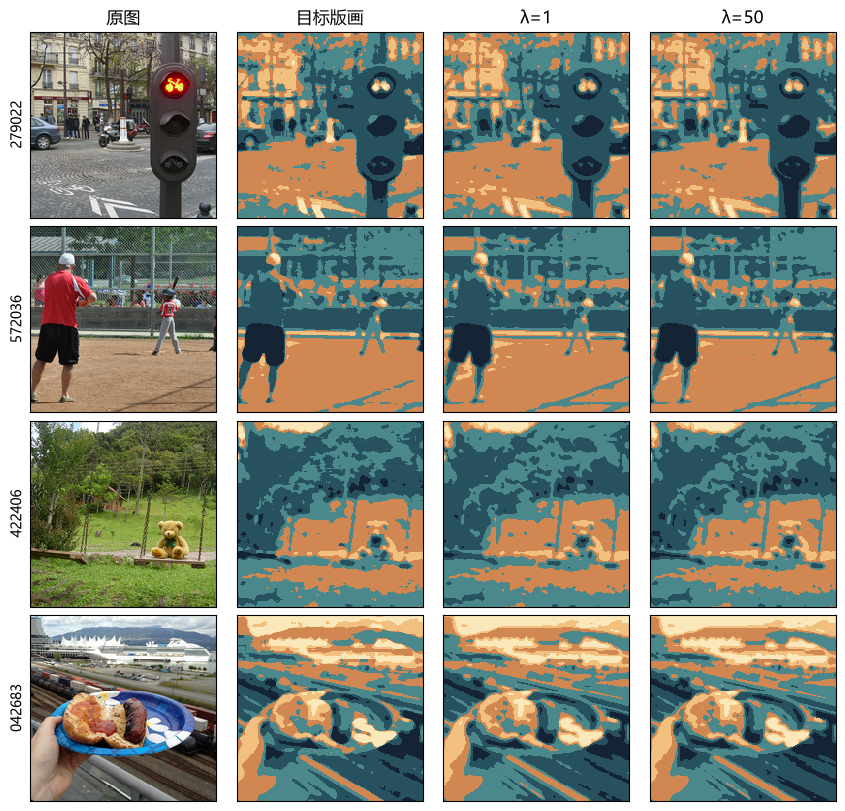

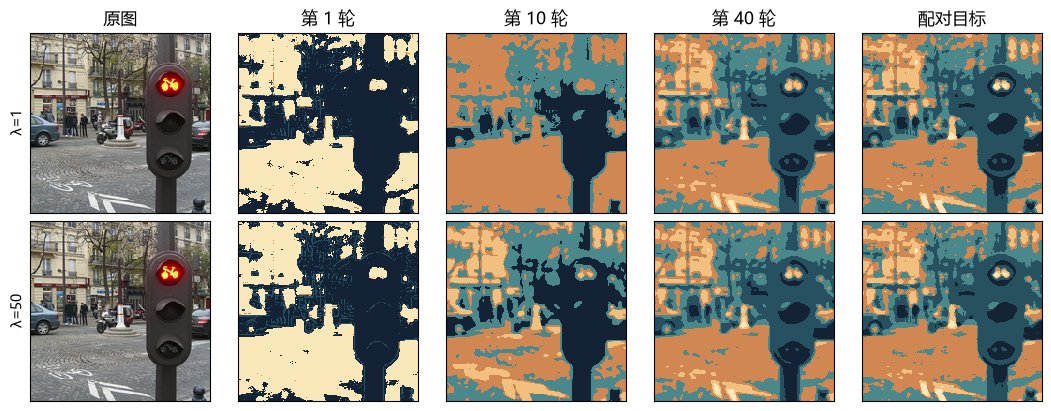

In [5]:
rows = []; ids = index.loc[index.split=='test','image_id'].tolist()
for size,(xs,targets) in test_sets.items():
    for weight in weights:
        for image_id,p,t in zip(ids,predictions[weight,size],targets):
            a,b = PALETTE[p.numpy()]/255,PALETTE[t.numpy()]/255
            rows.append([image_id,size,weight,np.abs(a-b).mean(),structural_similarity(a,b,data_range=1,channel_axis=2),(p==t).float().mean().item()])
scores = pd.DataFrame(rows,columns=['image_id','size','lambda_l1','MAE','SSIM','pixel_accuracy'])
scores.to_csv(out/'per_image.csv',index=False)
summary = scores.groupby(['size','lambda_l1']).mean(numeric_only=True)
summary.to_csv(out/'metrics.csv'); display(summary)
fig,axes = plt.subplots(1,3,figsize=(11,3.3),layout='constrained')
for ax,col,title in zip(axes,['adversarial','l1','discriminator'],['生成器对抗损失','生成器重构损失','判别器损失']):
    for weight,h in hist.groupby('lambda_l1'): ax.plot(h.epoch,h[col],label=f'λ={weight}')
    ax.set(title=title,xlabel='训练轮次',ylabel='损失'); ax.legend()
fig.savefig(out/'loss.png',dpi=160); plt.show()
def grid(rows, titles, labels, path):
    fig,axes = plt.subplots(len(rows),len(titles),figsize=(2.1*len(titles),2*len(rows)),layout='constrained')
    for i,row in enumerate(rows):
        for j,img in enumerate(row):
            ax = axes[i,j]; ax.imshow(img,interpolation="nearest"); ax.set(xticks=[],yticks=[])
            if i==0: ax.set_title(titles[j])
            if j==0: ax.set_ylabel(labels[i])
    fig.savefig(out/path,dpi=150); plt.show()
test_x,labels = test_sets[192]
grid([[rgb(test_x[i]),PALETTE[labels[i].numpy()],*[PALETTE[predictions[w,192][i].numpy()] for w in weights]] for i in range(4)],
     ['原图','目标版画','λ=1','λ=50'],[s[-6:] for s in ids[:4]],'comparison.png')
grid([[rgb(test_x[0]),*[evolution[w,e] for e in [1,10,40]],PALETTE[labels[0].numpy()]] for w in weights],
     ['原图','第 1 轮','第 10 轮','第 40 轮','配对目标'],[f'λ={w}' for w in weights],'evolution.png')